# Formulación publicada con destinos: comparar TopoSort y un óptimo entero demostrado

**Pregunta:** ¿Qué demuestra un modelo binario completo de destinos más allá de una heurística factible?

**Nivel**: 3

**Prerrequisitos**: destination-choice levels 1 and 2

**Tiempo de lectura**: 40 minutes

## Objetivos

Ejecuta la formulación binaria PCPSP publicada mediante OreBlocks en la misma instancia con semilla que TopoSort con destinos. Compara el plan constructivo, la reoptimización local restringida, el resultado exacto completo y la cota LP superior. La lección estudia el estado de prueba y conserva una entrada, un modelo de recursos y una convención de descuento.

This level moves from a constructive answer to a proof-backed benchmark. It uses the product's own package API instead of copying the mathematical model into notebook code. Every compared method receives one freshly generated instance, and each returned period-destination array is scored through the same evaluator. Follow the execution order: establish the relaxed reference, construct two feasible plans, solve the full binary problem, then reconcile and compare the outputs.

## Preparación

Desde la raíz del repositorio, instala el entorno exacto fijado. Esta celda informa las versiones importadas. El notebook no instala paquetes durante la ejecución.

```bash
pip install oreblocks==0.6.3 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Importa el paquete fijado, las herramientas gráficas y el constructor de instancias de PhaseFlow.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.3
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

El ejemplo usa una veta sintética de 48 bloques, generada con semilla 31 por el constructor MIT de PhaseFlow y OreBlocks 0.6.3. El manifiesto twin-vein comprometido se consulta sólo como contexto de procedencia; el plan se calcula desde una reconstrucción explícita del caso. MineLib no se usa: su resultado Newman1 es un agregado CPIT con destino fijo y condiciones académicas de descarga, no datos redistribuibles por bloque ni un comparador PCPSP.

Reconstruiremos el caso docente documentado en vez de copiar su traza como resultado. La semilla 31 fija el depósito generado. El manifiesto `data/derived/manifests/twin-vein.json` conserva el escenario y los métodos comprometidos; los arreglos de bloques se generan nuevamente mediante el pipeline. Las fuentes tienen roles distintos: el manifiesto aporta procedencia y el generador con semilla es la entrada experimental. A deterministic seed supports repeatability, not geological truth. The small case is deliberately used to make destination alternatives and period assignments inspectable. The code below rebuilds exactly the dimensions and scenario stated here; when experimenting, alter the seed explicitly and record every changed capacity or economic assumption.

Build the input through PhaseFlow's typed `Case` and `Scenario` contract. The two resource rows represent mining and processing; their fractions are capacity assumptions, not measured plant limits. We inspect the contract report before passing the instance to the scheduling methods.

In [2]:
# Reconstruye la instancia docente con semilla y lee el registro de procedencia comprometido.
case = Case(
    id='nb-destination-vein-4x4x3', category='teaching',
    title_en='Destination lesson', title_es='Leccion de destinos',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
                      capacity_fraction=(0.70, 0.50),
                      resource_names=('extraccion', 'procesamiento')),
)
instance = build_instance(case)
manifest = json.loads(Path('../../../data/derived/manifests/twin-vein.json').read_text(encoding='utf-8'))
print('contrato aceptado:', instance.report.ok)
print('bloques:', instance.n_blocks, '| recursos:', instance.pcpsp.n_resources,
      '| destinos:', instance.pcpsp.n_destinations)
print('caso de procedencia comprometido:', manifest['case_id'])

contrato aceptado: True
bloques: 48 | recursos: 2 | destinos: 2
caso de procedencia comprometido: twin-vein


## Método

Esta es una comparación de investigación en una instancia pequeña, no una reproducción de un resultado publicado. Jelvez, Morales y Nancel-Penard formulan el destino del bloque y el período de extracción como una decisión binaria conjunta. La referencia describe PCPSP, alternativas de destino y restricciones laterales; esta instancia de PhaseFlow tiene dos destinos y no incluye restricciones de mezcla. Declaramos qué parte está representada y dejamos fuera las restricciones ausentes.

El método `solve_opbsp_exact` implementa el modelo binario de Jelvez et al. (ecuaciones 3-10). Sea z[b,d,t] uno cuando el bloque b se extrae en el período t y se envía al destino d. En PhaseFlow el período 1 no se descuenta, así que D[t]=(1+r)^-(t-1). El modelo entero es:

```text
max  sum_(b,d,t) D[t] v[b,d] z[b,d,t]
s.a. sum_(d,t) z[b,d,t] <= 1                            para cada bloque b
    sum_(d,s<=t) z[b,d,s] <= sum_(d,s<=t) z[a,d,s]     para cada arco a->b y período t
    sum_(b,d) q[r,b,d] z[b,d,t] <= L[r,t]              para cada recurso r y período t
    z[b,d,t] = 0                                       para asignaciones prohibidas
    z[b,d,t] in {0,1}
```

El objetivo descuenta el valor del destino elegido; cada fila de recursos cobra el coeficiente de ese destino en el período seleccionado. Una sola variable binaria contiene ambas decisiones. Así se modelan destinos sin fijar un corte ni reducir a CPIT. La instancia es intencionalmente pequeña: 48 bloques, dos destinos y cuatro períodos.

Resolvemos la relajación LP con los mismos objetos `Pcpsp` y `Precedence`. Como su región factible incluye decisiones fraccionales de período y destino, su óptimo es una cota superior para el modelo entero. No es un plan factible. Conservamos estado `optimal`, objetivo, cantidad de variables y filas como evidencia. La heurística y el solver entero completo deben usar esos mismos objetos; comparar con otra instancia o un modelo de destino fijo no aislaría el algoritmo.

Las corridas LP y entera deben coincidir en datos, descuento, precedencia, recursos y alternativas de destino. Esta celda resuelve primero el modelo relajado e imprime dimensiones y estado; su objetivo será la cota superior del resultado entero.

In [3]:
# Resuelve la relajación LP con destinos para obtener una cota superior.
relaxation = ob.pcpsp_lp_bound(instance.pcpsp, instance.precedence,
                                max_rows=1500000, time_limit=20,
                                solution=True)
print('estado LP:', relaxation.status)
print('variables:', relaxation.n_variables, '| filas:', relaxation.n_rows)
print('cota superior PCPSP:', round(relaxation.bound, 2))

estado LP: optimal
variables: 576 | filas: 1144
cota superior PCPSP: 311484.31


Calculamos TopoSort con destinos antes del solver exacto. Mantener el incumbente permite interpretar el óptimo como mejora medida, con todas las decisiones evaluadas bajo el mismo modelo.

In [4]:
# Construye la referencia factible con elección de destino.
toposort_plan = ob.destination_toposort(instance.pcpsp,
                                         instance.precedence)
print('NPV TopoSort:', round(toposort_plan.npv, 2))
print('TopoSort exacto:', toposort_plan.exact)
print('bloques TopoSort:', toposort_plan.mined_blocks)

NPV TopoSort: 179593.14
TopoSort exacto: False
bloques TopoSort: 16


TopoSort con destinos es la referencia constructiva. Elige posiciones factibles respetando disponibilidad de predecesores y capacidad específica de cada destino. La búsqueda local restringida usa un incumbente y reoptimiza en conjunto períodos y destinos dentro de un vecindario. La resolución puede ser exacta para sus variables libres, pero la secuencia de vecindarios muestreados no es exacta para el problema completo. Sólo el solver binario completo puede probar optimalidad global aquí, y únicamente si termina con el estado óptimo del paquete.

Incluimos búsqueda local restringida como segunda comparación algorítmica. Resuelve exactamente vecindarios elegidos y puede mejorar el incumbente, pero no certifica el PCPSP completo. Semilla fija y pocos vecindarios hacen el experimento reproducible.

In [5]:
# Ejecuta la reoptimización restringida con semilla; no prueba el modelo completo.
local_plan = ob.exact_destination_local_search(
    instance.pcpsp, instance.precedence, toposort_plan,
    d_max=48, rounds=2, seed=13, time_limit=1.0, mip_gap=0.001)
print('NPV de búsqueda local restringida:', round(local_plan.npv, 2))
print('busqueda local restringida exacta globalmente:', False)

NPV de búsqueda local restringida: 237344.67
busqueda local restringida exacta globalmente: False


## Estado del arte

Ahora ejecutamos la formulación binaria publicada en vez de inferir su valor desde una heurística. La misma entrada y las mismas capacidades se conservan. El solver sólo devuelve una programación al demostrar optimalidad; en este caso de 48 bloques basta el presupuesto explícito de 30 segundos. Una instancia mayor puede devolver correctamente ningún resultado exacto bajo el mismo presupuesto.

El tiempo de pared cambia según el equipo y la carga, por eso no forma parte del resultado comprometido. La llamada exacta conserva límite de 30 segundos, presupuesto explícito de variables y brecha MIP. Si no demuestra optimalidad, `solve_opbsp_exact` no devuelve plan y el notebook arroja un error en vez de rotular un incumbente como exacto. Esto difiere de una heurística que devuelve una solución factible sin probar el resto del espacio de búsqueda.

Esta es la resolución completa del modelo entero respaldada por la literatura. La función devuelve `None` si el solver binario no demuestra optimalidad, por lo que la ausencia de resultado es deliberada. El límite temporal está visible; ninguna heurística se etiqueta como exacta.

In [6]:
# Exige que el solver binario completo demuestre optimalidad.
exact_plan = ob.solve_opbsp_exact(
    instance.pcpsp, instance.precedence, max_variables=40000,
    time_limit=30, mip_gap=0.0001)
if exact_plan is None:
    raise RuntimeError('el solver binario no demostró optimalidad')
print('prueba de optimalidad:', exact_plan.exact)
print('NPV exacto:', round(exact_plan.npv, 2))
print('bloques del plan exacto:', exact_plan.mined_blocks)


prueba de optimalidad: True
NPV exacto: 237344.67
bloques del plan exacto: 4


El evaluador público recalcula valor descontado y uso de recursos del arreglo exacto. Su coincidencia con el objetivo del solver reconcilia de forma independiente las decisiones de destino. También imprimimos el indicador de exactitud: sin estado de prueba, un valor aislado sería ambiguo.

El resultado del método incluye exactitud, NPV, conteo de bloques y el objetivo de una llamada independiente a `pcpsp_schedule_value`. La coincidencia entre método y evaluador confirma que los arreglos de período y destino se interpretan con la misma economía almacenada. El evaluador no demuestra precedencia ni optimalidad entera; esas propiedades corresponden al solver y sus restricciones. El gráfico compara resultados, pero conserva su procedencia en los valores impresos.

In [7]:
# Recalcula por separado el objetivo entero y el uso de recursos por período.
scored_npv, exact_use = ob.pcpsp_schedule_value(
    instance.pcpsp, exact_plan.period_of_block,
    exact_plan.destination_of_block)
print('NPV del objeto exacto:', round(exact_plan.npv, 2))
print('scored NPV exacto:', round(scored_npv, 2))
print('uso de recursos del plan exacto:', np.round(exact_use, 1))
print('límites de recursos declarados:', np.round(instance.pcpsp.limit, 1))

NPV del objeto exacto: 237344.67
scored NPV exacto: 237344.67
uso de recursos del plan exacto: [[5400. 5400.    0.    0.]
 [5400. 5400.    0.    0.]]
límites de recursos declarados: [[13230. 13230. 13230. 13230.]
 [ 6075.  6075.  6075.  6075.]]


The local search also returns an exact solution for its sampled restricted neighborhoods. We keep that statement distinct from the whole-problem proof. Its objective is useful for understanding this particular experiment, but only the full binary solve below supplies an exact benchmark for all period-destination assignments.

In [8]:
# Evalúa el incumbente restringido con el mismo evaluador público.
local_score, local_use = ob.pcpsp_schedule_value(
    instance.pcpsp, local_plan.period_of_block,
    local_plan.destination_of_block)
print('NPV del objeto de búsqueda local:', round(local_plan.npv, 2))
print('NPV recalculado de busqueda local:', round(local_score, 2))
print('NPV TopoSort:', round(toposort_plan.npv, 2))
print('cota superior LP:', round(relaxation.bound, 2))

NPV del objeto de búsqueda local: 237344.67
NPV recalculado de busqueda local: 237344.67
NPV TopoSort: 179593.14
cota superior LP: 311484.31


Las barras muestran tres planes factibles y la cota superior relajada. La diferencia TopoSort-óptimo es oportunidad heurística; óptimo-LP es holgura de la relajación fraccional. Que una heurística restringida iguale este óptimo es evidencia para una semilla; el estado del solver binario fundamenta la exactitud.

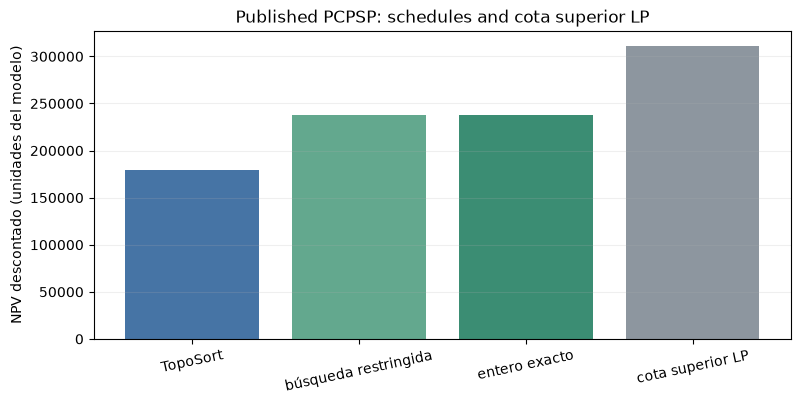

In [9]:
# Compara planes factibles y la cota superior en el mismo eje.
labels = ['TopoSort', 'búsqueda restringida', 'entero exacto', 'cota superior LP']
values = [toposort_plan.npv, local_score, scored_npv, relaxation.bound]
colors = ['#4674a5', '#63a88e', '#3b8d73', '#8d969f']
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, values, color=colors)
ax.set(title='Published PCPSP: schedules and cota superior LP',
       ylabel='NPV descontado (unidades del modelo)')
ax.tick_params(axis='x', rotation=12)
ax.grid(axis='y', alpha=0.2)
plt.show()

Las barras muestran tres planes factibles y la cota superior relajada. La diferencia TopoSort-óptimo es oportunidad heurística; óptimo-LP es holgura de la relajación fraccional. Que una heurística restringida iguale este óptimo es evidencia para una semilla; el estado del solver binario fundamenta la exactitud.

El siguiente gráfico cambia del objetivo al patrón de asignación. Usa las mismas decisiones de período y destino para la referencia y el óptimo demostrado, por lo que los cambios en el conteo de bloques se interpretan como consecuencia del modelo y no de otra entrada.

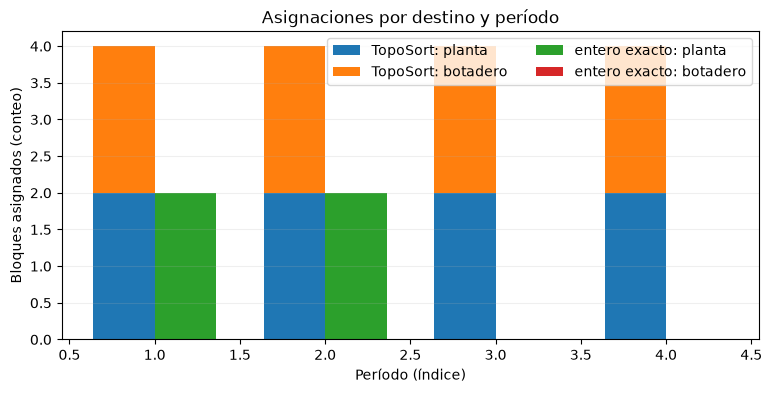

In [10]:
# Compara cómo los planes heurístico y exacto asignan bloques en el tiempo.
periods = np.arange(1, instance.pcpsp.n_periods + 1)
fig, ax = plt.subplots(figsize=(9, 4))
width = 0.36
for offset, plan, name in [(-width / 2, toposort_plan, 'TopoSort'),
                           (width / 2, exact_plan, 'entero exacto')]:
    plant_counts = [int(np.sum((plan.period_of_block == t) &
                               (plan.destination_of_block == 1)))
                    for t in range(instance.pcpsp.n_periods)]
    waste_counts = [int(np.sum((plan.period_of_block == t) &
                               (plan.destination_of_block == 0)))
                    for t in range(instance.pcpsp.n_periods)]
    ax.bar(periods + offset, plant_counts, width, label=f'{name}: planta')
    ax.bar(periods + offset, waste_counts, width, bottom=plant_counts,
           label=f'{name}: botadero')
ax.set(title='Asignaciones por destino y período', xlabel='Período (índice)',
       ylabel='Bloques asignados (conteo)')
ax.legend(ncol=2)
ax.grid(axis='y', alpha=0.2)
plt.show()

Las barras agrupadas cuentan asignaciones por destino y período para el plan constructivo y el exacto. Hacen visible el intercambio de programación, pero los conteos no son toneladas ni flujo de caja. Menos bloques pueden producir mayor NPV cuando capacidades, economía de destinos y descuento favorecen un conjunto menor.

## Resultados

**Respuesta:** el solver binario demostró un NPV exacto de 237344.67, superior a TopoSort con 179593.14 e igual a la búsqueda local restringida con 237344.67; la cota LP superior fue 311484.31. La comparación separa mejora de plan factible y holgura de relajación. La afirmación exacta corresponde sólo a esta instancia codificada de 48 bloques.

El objetivo citado del solver exacto se contrasta con el evaluador del paquete y los otros métodos.

In [11]:
# Imprime los resultados medidos citados arriba.
print(f'exacto={scored_npv:.2f}; TopoSort={toposort_plan.npv:.2f}; '
      f'busqueda_local={local_score:.2f}; cota={relaxation.bound:.2f}')

exacto=237344.67; TopoSort=179593.14; busqueda_local=237344.67; cota=311484.31


## Resumen

El modelo binario completo demuestra 237344.67 para esta instancia PCPSP con semilla; TopoSort obtiene 179593.14, la búsqueda local restringida alcanza aquí el mismo óptimo y la cota LP es 311484.31. La prueba proviene del estado óptimo del solver completo. Sólo vale para estos 48 bloques, capacidades, destinos y valores económicos.

Las barras responden dos preguntas. La diferencia entre TopoSort y el óptimo demostrado indica el valor capturado al mejorar el plan factible para esta semilla. La diferencia entre objetivo entero exacto y cota LP indica holgura de relajación. Que la búsqueda local iguale al óptimo en esta corrida es una observación empírica, no una prueba de que siempre lo encuentre. La exactitud pertenece al resultado óptimo del modelo completo, no a la barra que parezca mejor.

El gráfico de asignaciones cuenta bloques de planta y botadero por período para TopoSort y el óptimo exacto. Muestra que el óptimo entero puede extraer menos bloques y aun así obtener mayor valor: la función objetivo maximiza valor descontado bajo límites de recursos, no cantidad total de bloques. El gráfico no contiene toneladas ni leyes y no reemplaza el uso de recursos ni los flujos económicos por destino. Explica la estructura de los dos arreglos devueltos.

El óptimo demostrado es 237344.67 unidades del modelo para la veta y el escenario generados. Es el óptimo exacto del modelo entero codificado de 48 bloques, sujeto a convenciones numéricas del solver. La cota LP de 311484.31 permanece por encima porque permite decisiones fraccionales. Esto es esperado: no indica que falló la resolución exacta ni implica que la relajación sea ajustada en casos mayores.

Los casos reportados en el artículo no generan las cifras de este notebook. El artículo aporta el contexto de formulación; el generador con semilla de PhaseFlow aporta los datos. Newman1 de MineLib es otro benchmark CPIT agregado con destino fijo y queda fuera del experimento PCPSP. Tampoco se modelan mezclas, acopios, incertidumbre geológica ni restricciones operacionales de toda la mina. El hallazgo es acotado: para esta entrada docente, el solver prueba el óptimo PCPSP y permite comparar las heurísticas mostradas.

## Referencias

- Jelvez, Morales y Nancel-Penard (2018), programación de rajos con destinos: https://www.delphoslab.cl/Publicaciones/2018/Jelvez_et_al_MPES2018.pdf
- Constructor de instancias sintéticas y pipeline de PhaseFlow: https://github.com/fsantibanezleal/CAOS_PhaseFlow
- Dossier PhaseFlow: docs/methodologies/09_destinations.md